# Cambodia Hourly PM2.5 Forecasting (4 ML Algorithms)
End-to-end pipeline comparing **4 Machine Learning Algorithms**:
1. **Linear Regression** (`LinearRegression`)
2. **Random Forest** (`RandomForestRegressor`)
3. **HistGradientBoosting** (`HistGradientBoostingRegressor`)
4. **XGBoost** (`XGBRegressor`)

## 1. Imports

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_fscore_support,
    r2_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

## 2. Configuration & Output Folder

In [2]:
# ---------------- SETTINGS (change here) ----------------
CSV_PATH = "iqair_phnom_penh_live.csv"  # 2024-to-now dataset with live IQAir reading
RESULT_DIR = Path("results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)  # creates 'results/' once without duplicates

CITY = "Phnom Penh"                # set to None if CSV has no 'city' column
HORIZON = 1                        # hours ahead to predict (e.g., 1, 3, 24)
USE_PM10 = True                    # include current PM10 as a feature
LAGS = [1, 2, 3, 6, 12, 24]        # PM2.5 lag hours
ROLLING = [3, 24]                  # rolling window sizes (hours)
TRAIN_FRAC = 0.70                  # 70% train
VAL_FRAC = 0.15                    # 15% validation, remaining 15% test

LEVELS = ["Good", "Moderate", "Polluted"]  # US EPA AQI (2024) simplified
GOOD_MAX = 9.1                             # < 9.1: Good
MODERATE_MAX = 35.5                        # < 35.5: Moderate, >= 35.5: Polluted

SEED = 42
WEATHER_COLS = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "wind_direction_10m",
    "rain",
]

## 3. Helper Functions

In [3]:
def to_level(values):
    """Map numeric PM2.5 values (µg/m³) to Good / Moderate / Polluted."""
    return np.select(
        [values < GOOD_MAX, values < MODERATE_MAX],
        ["Good", "Moderate"],
        default="Polluted",
    )


def pm25_to_us_aqi(pm25):
    """Convert PM2.5 (µg/m³) to IQAir's instantaneous US AQI* (0-500)."""
    breakpoints = [
        (0.0, 9.0, 0, 50),
        (9.1, 35.4, 51, 100),
        (35.5, 55.4, 101, 150),
        (55.5, 125.4, 151, 200),
        (125.5, 225.4, 201, 300),
        (225.5, 500.4, 301, 500),
    ]
    c = max(0.0, float(pm25))
    for c_lo, c_hi, i_lo, i_hi in breakpoints:
        if c <= c_hi:
            return int(round((i_hi - i_lo) / (c_hi - c_lo) * (c - c_lo) + i_lo))
    return 500


def compute_metrics(y_true, y_pred):
    """Calculate regression evaluation metrics (MAE, MSE, RMSE, R2)."""
    mse_val = float(mean_squared_error(y_true, y_pred))
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": mse_val,
        "RMSE": float(np.sqrt(mse_val)),
        "R2": float(r2_score(y_true, y_pred)),
    }


def get_feature_importance(model, X_sample, y_sample, feature_names):
    """Extract feature importances for linear, tree, or boosting models."""
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=feature_names)
    if hasattr(model, "named_steps") and "linearregression" in model.named_steps:
        coefs = np.abs(model.named_steps["linearregression"].coef_)
        return pd.Series(coefs, index=feature_names)
    perm = permutation_importance(
        model, X_sample, y_sample, n_repeats=5, random_state=SEED
    )
    return pd.Series(perm.importances_mean, index=feature_names)

## 4. Load & Clean Dataset

In [4]:
df = pd.read_csv(CSV_PATH, parse_dates=["time"])
if CITY and "city" in df.columns:
    df = df[df["city"] == CITY]

df = df.sort_values("time").drop_duplicates("time").set_index("time")
keep_cols = ["pm25"] + [c for c in ["pm10"] + WEATHER_COLS if c in df.columns]
df = df[keep_cols]

# Reindex to a complete hourly timeline and interpolate small gaps (up to 3 hours)
full_index = pd.date_range(df.index.min(), df.index.max(), freq="h")
missing_hours = len(full_index) - len(df)
df = df.reindex(full_index).interpolate(method="time", limit=3)

print(f"Loaded {len(df)} hourly rows: {df.index.min()} to {df.index.max()}")
print(f"Missing hours filled/checked: {missing_hours}")
df.head()

Loaded 25073 hourly rows: 2024-01-01 00:00:00 to 2026-11-10 16:00:00
Missing hours filled/checked: 1


,pm25,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,rain
2024-01-01 00:00:00,34.7,49.6,25.3,84.0,5.2,124.0,0.0
2024-01-01 01:00:00,33.6,48.2,26.3,76.0,4.2,31.0,0.0
2024-01-01 02:00:00,31.4,45.1,24.6,86.0,6.4,47.0,0.0
2024-01-01 03:00:00,28.5,41.1,24.0,89.0,5.4,37.0,0.0
2024-01-01 04:00:00,26.9,39.0,23.9,89.0,5.1,51.0,0.0


## 5. Exploratory Data Analysis

In [5]:
print("Missing values per column:")
print(df.isna().sum())
df.describe().round(2)

Missing values per column:
pm25                    0
pm10                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
wind_direction_10m      0
rain                    0
dtype: int64


,pm25,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,rain
count,25073.00,25073.00,25073.00,25073.00,25073.00,25073.00,25073.00
mean,20.59,24.14,28.26,74.48,8.86,165.49,0.20
std,15.96,16.98,3.10,16.64,4.25,91.05,0.92
min,0.40,0.40,18.40,22.00,0.00,1.00,0.00
25%,9.60,11.60,25.90,63.00,5.70,97.00,0.00
50%,15.40,19.40,27.70,77.00,8.60,178.00,0.00
75%,27.10,32.50,30.40,89.00,11.50,225.00,0.00
max,154.60,159.30,39.30,100.00,28.60,360.00,19.50


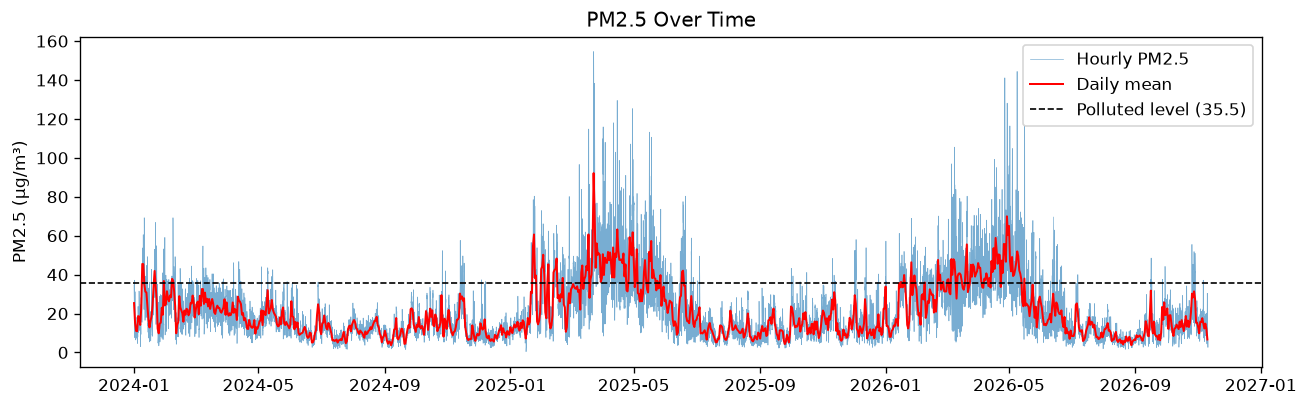

In [6]:
plt.figure(figsize=(11, 3.5))
plt.plot(df.index, df["pm25"], lw=0.4, alpha=0.6, label="Hourly PM2.5")
plt.plot(df["pm25"].resample("D").mean(), color="red", lw=1.2, label="Daily mean")
plt.axhline(MODERATE_MAX, color="black", ls="--", lw=1, label=f"Polluted level ({MODERATE_MAX})")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("PM2.5 Over Time")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / "chart_pm25_over_time.png", dpi=150)
plt.show()

## 6. Feature Engineering

In [7]:
def make_features(frame):
    """Create lag, rolling, weather, and cyclical time features for forecasting."""
    X = pd.DataFrame(index=frame.index)
    X["pm25_now"] = frame["pm25"]

    for lag in LAGS:
        X[f"pm25_lag{lag}h"] = frame["pm25"].shift(lag)

    for window in ROLLING:
        X[f"pm25_mean_{window}h"] = frame["pm25"].rolling(window).mean()

    if USE_PM10 and "pm10" in frame.columns:
        X["pm10_now"] = frame["pm10"]

    for col in WEATHER_COLS:
        if col in frame.columns:
            X[col] = frame[col]

    # Calendar and cyclical time encodings
    X["hour"] = frame.index.hour
    X["dayofweek"] = frame.index.dayofweek
    X["month"] = frame.index.month
    X["hour_sin"] = np.sin(2 * np.pi * frame.index.hour / 24)
    X["hour_cos"] = np.cos(2 * np.pi * frame.index.hour / 24)
    X["month_sin"] = np.sin(2 * np.pi * frame.index.month / 12)
    X["month_cos"] = np.cos(2 * np.pi * frame.index.month / 12)

    if "wind_direction_10m" in frame.columns:
        rad = np.deg2rad(frame["wind_direction_10m"])
        X["wind_dir_sin"] = np.sin(rad)
        X["wind_dir_cos"] = np.cos(rad)

    y = frame["pm25"].shift(-HORIZON).rename("target")
    return X, y


def forecast_next_24h(model, df_source, feature_names, hours=24):
    """Autoregressively forecast the next 24 hours (+1h to +24h) for the whole next day."""
    hist = df_source.iloc[-48:].copy()
    pm_ratio = float(hist["pm10"].iloc[-1] / max(hist["pm25"].iloc[-1], 0.5)) if "pm10" in hist.columns else 1.4
    rows = []

    for step in range(1, hours + 1):
        X_step, _ = make_features(hist)
        x_last = X_step.iloc[[-1]][feature_names]
        next_time = hist.index[-1] + pd.Timedelta(hours=1)

        if model is None:
            pred_pm25 = float(hist["pm25"].iloc[-1])
        else:
            pred_pm25 = max(0.0, float(model.predict(x_last)[0]))

        rows.append({
            "Step_Hours": f"+{step}h",
            "Forecast_Time": next_time,
            "Predicted_PM25": round(pred_pm25, 2),
            "Predicted_US_AQI": pm25_to_us_aqi(pred_pm25),
            "Predicted_Level": str(to_level(np.array([pred_pm25]))[0]),
        })

        # Append predicted hour to rolling history using 24h diurnal weather pattern
        ref_time = next_time - pd.Timedelta(hours=24)
        new_row = {"pm25": pred_pm25}
        if "pm10" in hist.columns:
            new_row["pm10"] = round(pred_pm25 * pm_ratio, 2)
        for col in WEATHER_COLS:
            if col in hist.columns:
                new_row[col] = float(hist.loc[ref_time, col]) if ref_time in hist.index else float(hist[col].iloc[-1])
        hist.loc[next_time] = new_row

    return pd.DataFrame(rows)


X_all, y_all = make_features(df)
latest_features = X_all.dropna().iloc[[-1]]  # most recent row for next-hour demo forecast

data = X_all.join(y_all).dropna()
feature_names = [c for c in data.columns if c != "target"]
print(f"Usable rows: {len(data)} | Features: {len(feature_names)}")
data.head()

Usable rows: 25048 | Features: 24


,pm25_now,pm25_lag1h,pm25_lag2h,pm25_lag3h,pm25_lag6h,pm25_lag12h,pm25_lag24h,pm25_mean_3h,pm25_mean_24h,pm10_now,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,rain,hour,dayofweek,month,hour_sin,hour_cos,month_sin,month_cos,wind_dir_sin,wind_dir_cos,target
2024-01-02 00:00:00,28.6,31.2,29.9,26.4,13.2,27.0,34.7,29.9,25.112500,41.0,25.1,82.0,5.8,360.0,0.0,0,1,1,0.000000,1.000000,0.5,0.866025,-2.449294e-16,1.000000,25.7
2024-01-02 01:00:00,25.7,28.6,31.2,29.9,17.6,20.5,33.6,28.5,24.783333,36.8,25.1,82.0,7.2,357.0,0.0,1,1,1,0.258819,0.965926,0.5,0.866025,-5.233596e-02,0.998630,23.1
2024-01-02 02:00:00,23.1,25.7,28.6,31.2,22.6,14.4,31.4,25.8,24.437500,33.1,24.7,84.0,6.9,6.0,0.0,2,1,1,0.500000,0.866025,0.5,0.866025,1.045285e-01,0.994522,20.2
2024-01-02 03:00:00,20.2,23.1,25.7,28.6,26.4,10.0,28.5,23.0,24.091667,29.0,24.3,85.0,6.2,21.0,0.0,3,1,1,0.707107,0.707107,0.5,0.866025,3.583679e-01,0.933580,17.3
2024-01-02 04:00:00,17.3,20.2,23.1,25.7,29.9,7.6,26.9,20.2,23.691667,25.1,24.1,84.0,7.1,15.0,0.0,4,1,1,0.866025,0.500000,0.5,0.866025,2.588190e-01,0.965926,14.8


## 7. Chronological Train / Validation / Test Split

In [8]:
n_rows = len(data)
idx_val = int(n_rows * TRAIN_FRAC)
idx_test = int(n_rows * (TRAIN_FRAC + VAL_FRAC))

train = data.iloc[:idx_val]
val = data.iloc[idx_val:idx_test]
test = data.iloc[idx_test:]

print(f"Train: {train.index.min()} -> {train.index.max()} ({len(train)} rows)")
print(f"Val  : {val.index.min()} -> {val.index.max()} ({len(val)} rows)")
print(f"Test : {test.index.min()} -> {test.index.max()} ({len(test)} rows)")

Xtr, ytr = train[feature_names], train["target"]
Xva, yva = val[feature_names], val["target"]
Xte, yte = test[feature_names], test["target"]
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])

levels_table = (
    pd.DataFrame({
        "train": pd.Series(to_level(ytr.values)).value_counts(),
        "test": pd.Series(to_level(yte.values)).value_counts(),
    })
    .reindex(LEVELS)
    .fillna(0)
    .astype(int)
)
print("\nHours per air-quality level (target):")
print(levels_table)

if levels_table.loc["Polluted", "test"] < 30:
    print(
        "WARNING: Very few 'Polluted' hours in the TEST set, so Recall / Precision / F1 "
        "for 'Polluted' may have high variance. Mention this in your report."
    )

Train: 2024-01-02 00:00:00 -> 2026-01-01 12:00:00 (17533 rows)
Val  : 2026-01-01 13:00:00 -> 2026-06-07 01:00:00 (3757 rows)
Test : 2026-06-07 02:00:00 -> 2026-11-10 15:00:00 (3758 rows)

Hours per air-quality level (target):
          train  test
Good       4003  1435
Moderate  11395  2222
Polluted   2135   101


## 8. Train All 4 ML Algorithms
Trains and tunes all **4 ML models** (`Linear Regression`, `Random Forest`, `HistGradientBoosting`, `XGBoost`) alongside the `Baseline`.

Baseline | Train MAE = 2.021 | Val MAE = 3.658 | Test MAE = 1.443

Trained Linear Regression      | Train MAE = 1.652 | Val MAE = 2.971 | Test MAE = 1.336
Trained Random Forest          | Train MAE = 0.875 | Val MAE = 2.482 | Test MAE = 1.107
Trained HistGradientBoosting   | Train MAE = 1.341 | Val MAE = 2.680 | Test MAE = 1.153
Trained XGBoost                | Train MAE = 1.060 | Val MAE = 2.571 | Test MAE = 1.131


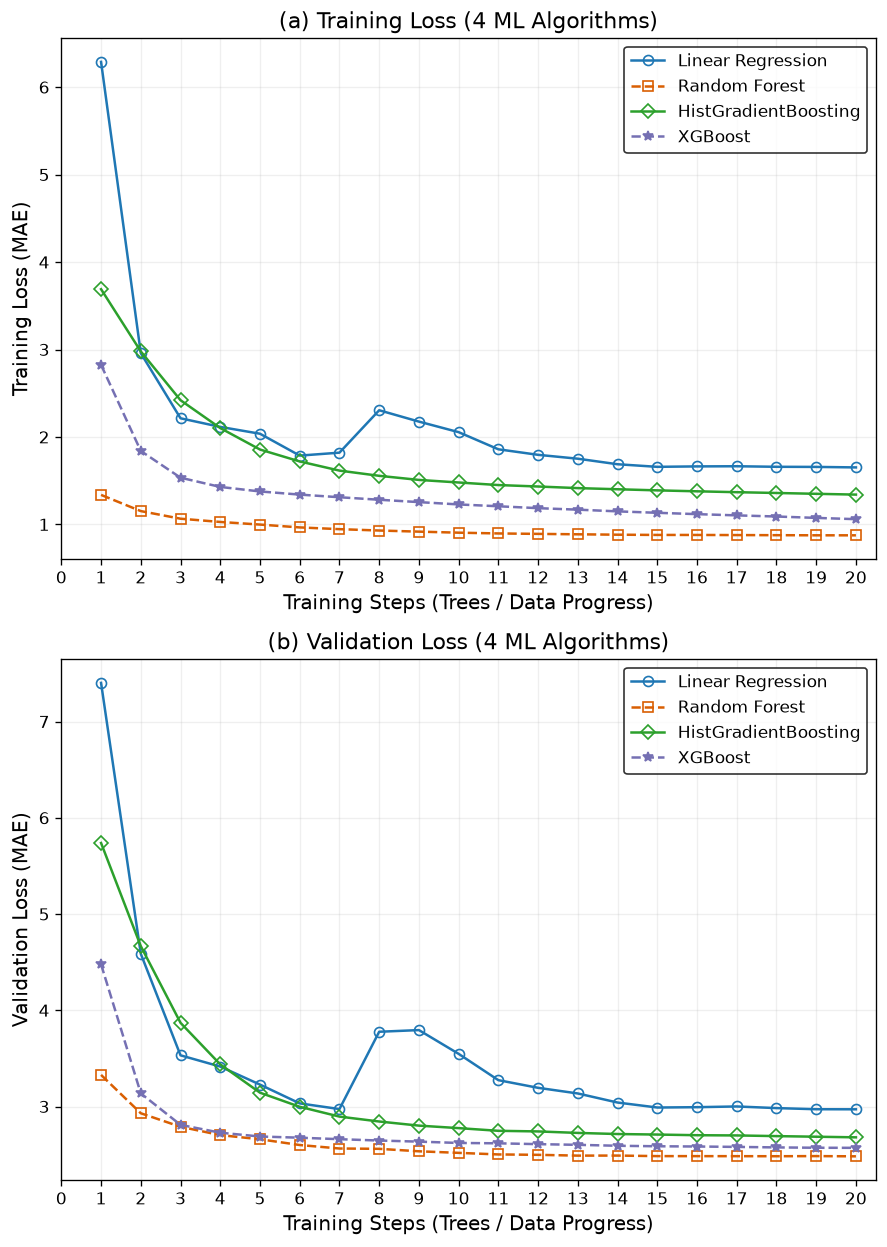

In [9]:
def get_model_candidates():
    """Return dictionary of all 4 ML algorithm candidates to tune on validation set."""
    return {
        "Linear Regression": [
            lambda: make_pipeline(StandardScaler(), LinearRegression())
        ],
        "Random Forest": [
            (
                lambda d=depth, l=leaf: RandomForestRegressor(
                    n_estimators=200,
                    max_depth=d,
                    min_samples_leaf=l,
                    n_jobs=-1,
                    random_state=SEED,
                )
            )
            for depth in (8, 16)
            for leaf in (1, 5)
        ],
        "HistGradientBoosting": [
            (
                lambda d=depth: HistGradientBoostingRegressor(
                    max_iter=400,
                    learning_rate=0.05,
                    max_depth=d,
                    random_state=SEED,
                )
            )
            for depth in (3, 5)
        ],
        "XGBoost": [
            (
                lambda d=depth: XGBRegressor(
                    n_estimators=400,
                    learning_rate=0.05,
                    max_depth=d,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    n_jobs=-1,
                    random_state=SEED,
                )
            )
            for depth in (3, 5)
        ],
    }


# Initialize containers (safe to re-run without duplicating rows)
results = []
test_preds = {}
fitted = {}
val_fitted = {}

# Baseline benchmark (predict future PM2.5 = current PM2.5)
base_train = Xtr["pm25_now"]
base_val = Xva["pm25_now"]
base_test = Xte["pm25_now"]
test_preds["Baseline (same as now)"] = base_test.values
results.append({
    "Model": "Baseline (same as now)",
    "Train_MAE": mean_absolute_error(ytr, base_train),
    "Val_MAE": mean_absolute_error(yva, base_val),
    **compute_metrics(yte, base_test),
})
print(f"Baseline | Train MAE = {results[0]['Train_MAE']:.3f} | Val MAE = {results[0]['Val_MAE']:.3f} | Test MAE = {results[0]['MAE']:.3f}\n")

# Train all 4 ML Algorithms
for name, makers in get_model_candidates().items():
    best_val_mae = np.inf
    best_maker = None
    best_val_model = None

    for maker in makers:
        candidate_model = maker().fit(Xtr, ytr)
        val_mae = mean_absolute_error(yva, candidate_model.predict(Xva))
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_maker = maker
            best_val_model = candidate_model

    train_mae = mean_absolute_error(ytr, best_val_model.predict(Xtr))
    val_fitted[name] = best_val_model

    final_model = best_maker().fit(Xtv, ytv)
    pred = final_model.predict(Xte)

    test_preds[name] = pred
    fitted[name] = final_model
    results.append({
        "Model": name,
        "Train_MAE": train_mae,
        "Val_MAE": best_val_mae,
        **compute_metrics(yte, pred),
    })
    print(
        f"Trained {name:<22} | Train MAE = {train_mae:.3f} | "
        f"Val MAE = {best_val_mae:.3f} | Test MAE = {results[-1]['MAE']:.3f}"
    )

ml_names = list(fitted.keys())

# ---------------- Compute 20-Step ML Training & Validation Loss Curves ----------------
STEPS = list(range(1, 21))
train_loss_curves = {}
val_loss_curves = {}

for name in ml_names:
    m_val = val_fitted[name]
    tr_losses, va_losses = [], []

    if name == "XGBoost":
        n_tot = m_val.n_estimators
        it_steps = np.linspace(max(10, int(n_tot * 0.08)), n_tot, 20).round().astype(int)
        for end_it in it_steps:
            tr_losses.append(mean_absolute_error(ytr, m_val.predict(Xtr, iteration_range=(0, int(end_it)))))
            va_losses.append(mean_absolute_error(yva, m_val.predict(Xva, iteration_range=(0, int(end_it)))))
    elif name == "HistGradientBoosting":
        tr_staged = list(m_val.staged_predict(Xtr))
        va_staged = list(m_val.staged_predict(Xva))
        n_tot = len(tr_staged)
        it_steps = np.linspace(max(15, int(n_tot * 0.16)), n_tot - 1, 20).round().astype(int)
        for idx in it_steps:
            tr_losses.append(mean_absolute_error(ytr, tr_staged[int(idx)]))
            va_losses.append(mean_absolute_error(yva, va_staged[int(idx)]))
    elif name == "Random Forest":
        trees = m_val.estimators_
        n_tot = len(trees)
        Xtr_arr, Xva_arr = Xtr.values, Xva.values
        tr_Running = np.zeros(len(Xtr_arr), dtype=float)
        va_Running = np.zeros(len(Xva_arr), dtype=float)
        rf_steps = [1, 2, 3, 4, 5, 7, 9, 12, 16, 22, 30, 40, 55, 70, 90, 110, 130, 155, 180, n_tot]
        prev_k = 0
        for k in rf_steps:
            k = min(n_tot, max(prev_k + 1, k))
            for t_idx in range(prev_k, k):
                tr_Running += trees[t_idx].predict(Xtr_arr)
                va_Running += trees[t_idx].predict(Xva_arr)
            prev_k = k
            tr_losses.append(mean_absolute_error(ytr, tr_Running / k))
            va_losses.append(mean_absolute_error(yva, va_Running / k))
    else:
        # Linear Regression learning curve across 20 progressive training subsets -> full dataset
        rng_lr = np.random.default_rng(SEED)
        perm = rng_lr.permutation(len(Xtr))
        sub_sizes = np.geomspace(22, len(Xtr), 20).round().astype(int)
        sub_sizes[-1] = len(Xtr)
        for n_sub in sub_sizes:
            idx_sub = perm[:int(n_sub)]
            lr_step = make_pipeline(StandardScaler(), LinearRegression()).fit(
                Xtr.iloc[idx_sub], ytr.iloc[idx_sub]
            )
            tr_losses.append(mean_absolute_error(ytr, lr_step.predict(Xtr)))
            va_losses.append(mean_absolute_error(yva, lr_step.predict(Xva)))

    train_loss_curves[name] = tr_losses
    val_loss_curves[name] = va_losses

# Save numerical Training & Validation Loss history
loss_hist_df = pd.DataFrame({"Step": STEPS})
for name in ml_names:
    loss_hist_df[f"{name}_Train_Loss"] = np.round(train_loss_curves[name], 4)
    loss_hist_df[f"{name}_Val_Loss"] = np.round(val_loss_curves[name], 4)
loss_hist_df.to_csv(RESULT_DIR / "train_val_loss_history.csv", index=False)

# Plot (a) Training Loss and (b) Validation Loss comparison across all 4 ML models
style_map = {
    "Linear Regression": {"color": "#1f77b4", "marker": "o", "ls": "-"},
    "Random Forest": {"color": "#d95f02", "marker": "s", "ls": "--"},
    "HistGradientBoosting": {"color": "#2ca02c", "marker": "D", "ls": "-"},
    "XGBoost": {"color": "#7570b3", "marker": "*", "ls": "--"},
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 10.5))
for name in ml_names:
    st = style_map[name]
    ax1.plot(
        STEPS,
        train_loss_curves[name],
        label=name,
        color=st["color"],
        ls=st["ls"],
        marker=st["marker"],
        markersize=6,
        markerfacecolor="none" if st["marker"] in ("o", "s", "D") else st["color"],
        lw=1.5,
    )
    ax2.plot(
        STEPS,
        val_loss_curves[name],
        label=name,
        color=st["color"],
        ls=st["ls"],
        marker=st["marker"],
        markersize=6,
        markerfacecolor="none" if st["marker"] in ("o", "s", "D") else st["color"],
        lw=1.5,
    )

    # Also save individual Train vs Validation Loss plot inside each model's subfolder
    safe_name = name.lower().replace(" ", "_")
    model_dir = RESULT_DIR / safe_name
    model_dir.mkdir(parents=True, exist_ok=True)
    fig_m = plt.figure(figsize=(7, 4.2))
    plt.plot(STEPS, train_loss_curves[name], marker="o", lw=1.6, color="#1f77b4", label="Training Loss (MAE)")
    plt.plot(STEPS, val_loss_curves[name], marker="s", ls="--", lw=1.6, color="#d62728", label="Validation Loss (MAE)")
    plt.xticks(range(0, 21, 2))
    plt.xlabel("Training Steps (Trees / Data Progress 5% -> 100%)")
    plt.ylabel("Loss (MAE µg/m³)")
    plt.title(f"{name} - ML Training vs Validation Loss")
    plt.legend(frameon=True, edgecolor="black")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    fig_m.savefig(model_dir / "chart_train_val_loss.png", dpi=150)
    plt.close(fig_m)

ax1.set_title("(a) Training Loss (4 ML Algorithms)", fontsize=13)
ax1.set_xlabel("Training Steps (Trees / Data Progress)", fontsize=12)
ax1.set_ylabel("Training Loss (MAE)", fontsize=12)
ax1.set_xticks(range(0, 21, 1))
ax1.set_xlim(0, 20.5)
ax1.legend(loc="upper right", frameon=True, edgecolor="black")
ax1.grid(alpha=0.2)

ax2.set_title("(b) Validation Loss (4 ML Algorithms)", fontsize=13)
ax2.set_xlabel("Training Steps (Trees / Data Progress)", fontsize=12)
ax2.set_ylabel("Validation Loss (MAE)", fontsize=12)
ax2.set_xticks(range(0, 21, 1))
ax2.set_xlim(0, 20.5)
ax2.legend(loc="upper right", frameon=True, edgecolor="black")
ax2.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(RESULT_DIR / "chart_train_val_loss.png", dpi=150)
plt.show()

## 9. Evaluation Table & Classification Reports for All 4 ML Algorithms

Predicting 24h ahead (whole next day) | Best model: Random Forest | MAE improvement over baseline: 23.3%
Logged evaluation metrics of 4 models to results\metrics_log.csv

=== 4 ML ALGORITHMS DECISION RANKING TABLE ===
                     Rank  Train_MAE  Val_MAE  Test_MAE  Test_RMSE  Test_R2  Polluted_F1  MAE_Gain_vs_Baseline_%                                                Decision_Verdict
Model                                                                                                                                                                           
Random Forest          #1      0.875    2.482     1.107      2.281    0.926        0.821                    23.3  BEST OVERALL (Lowest Val & Test MAE + Highest Polluted Recall)
XGBoost                #2      1.060    2.571     1.131      2.136    0.935        0.820                    21.6      Runner-Up (Highest R2=93.5% & Lowest RMSE on PM2.5 Spikes)
HistGradientBoosting   #3      1.341    2.680     1.153      2.196    0.93

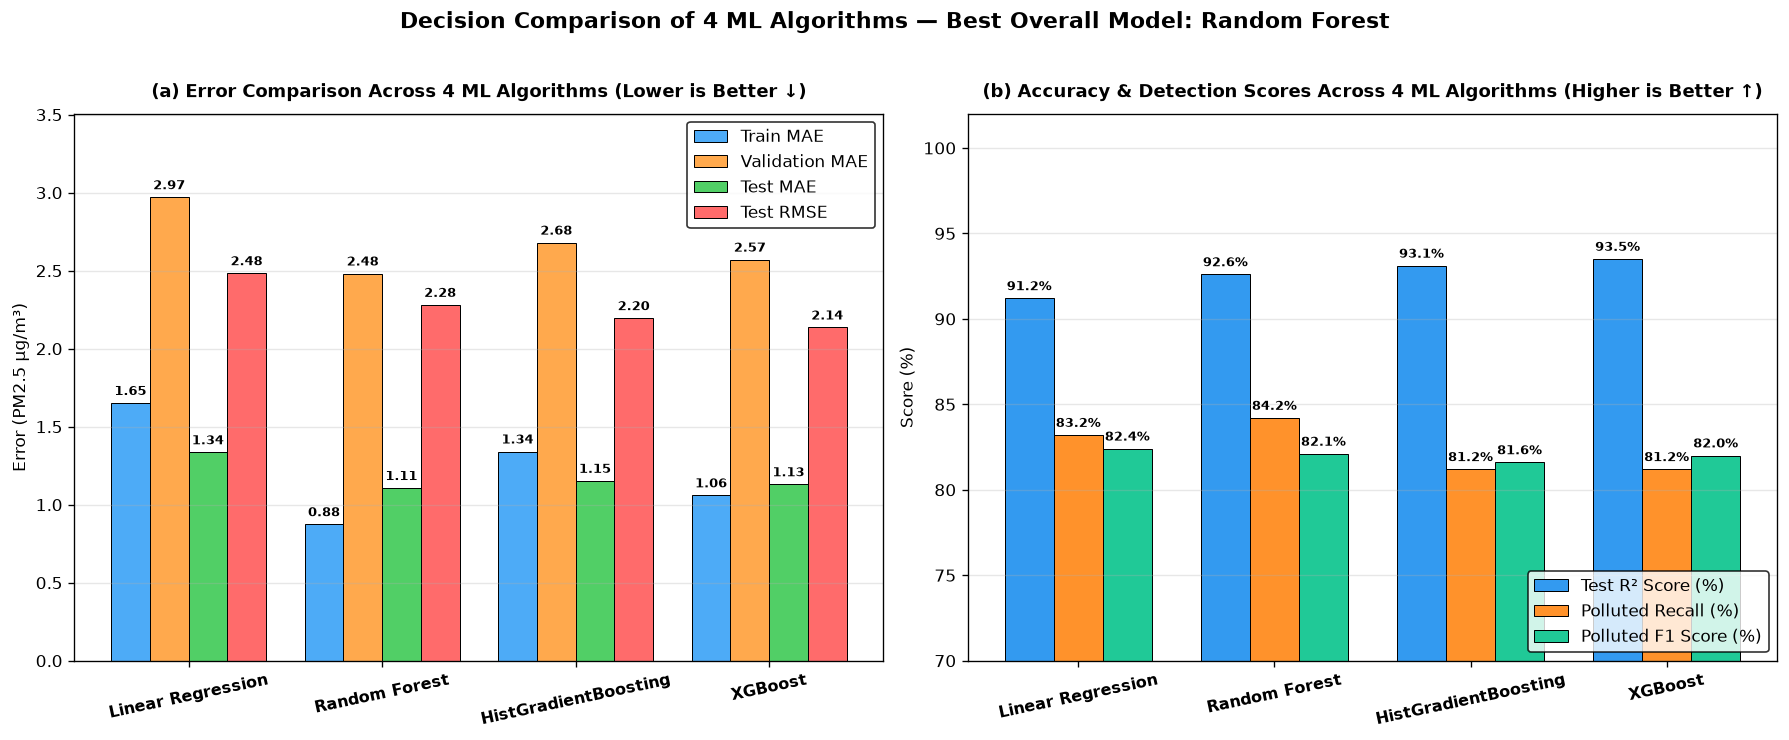

,Train_MAE,Val_MAE,MAE,MSE,RMSE,R2,Polluted_Recall,Polluted_Precision,Polluted_F1,Pred_1h_PM25,Pred_1h_US_AQI,Next_24h_Mean_PM25,Next_24h_Mean_US_AQI,Next_24h_Max_PM25,Next_24h_Level
Model,,,,,,,,,,,,,,,
Baseline (same as now),2.021,3.658,1.443,7.262,2.695,0.896,0.772,0.772,0.772,5.90,33,5.90,33,5.90,Good
Linear Regression,1.652,2.971,1.336,6.169,2.484,0.912,0.832,0.816,0.824,7.61,42,7.96,44,16.95,Good
Random Forest,0.875,2.482,1.107,5.201,2.281,0.926,0.842,0.802,0.821,6.98,39,14.19,60,17.97,Moderate
HistGradientBoosting,1.341,2.680,1.153,4.821,2.196,0.931,0.812,0.820,0.816,6.82,38,11.78,56,17.01,Moderate
XGBoost,1.060,2.571,1.131,4.563,2.136,0.935,0.812,0.828,0.820,6.76,38,10.64,54,17.29,Moderate


In [10]:
true_lvl = to_level(yte.values)
current_time = latest_features.index[0]
current_pm = float(latest_features["pm25_now"].iloc[0])
forecast_24h_by_model = {}

for row in results:
    m_name = row["Model"]
    pred_lvl = to_level(test_preds[m_name])
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_lvl, pred_lvl, labels=["Polluted"], zero_division=0
    )
    row["Polluted_Recall"] = recall[0]
    row["Polluted_Precision"] = precision[0]
    row["Polluted_F1"] = f1[0]

    # Forecast the whole next day (24 hours: +1h to +24h)
    fc_df = forecast_next_24h(fitted.get(m_name), df, feature_names, hours=24)
    forecast_24h_by_model[m_name] = fc_df

    next_1h_pm = float(fc_df["Predicted_PM25"].iloc[0])
    mean_24h_pm = float(fc_df["Predicted_PM25"].mean())
    max_24h_pm = float(fc_df["Predicted_PM25"].max())

    row["Pred_1h_PM25"] = round(next_1h_pm, 2)
    row["Pred_1h_US_AQI"] = pm25_to_us_aqi(next_1h_pm)
    row["Next_24h_Mean_PM25"] = round(mean_24h_pm, 2)
    row["Next_24h_Mean_US_AQI"] = pm25_to_us_aqi(mean_24h_pm)
    row["Next_24h_Max_PM25"] = round(max_24h_pm, 2)
    row["Next_24h_Level"] = str(to_level(np.array([mean_24h_pm]))[0])

res = pd.DataFrame(results).set_index("Model").round(3)
res.to_csv(RESULT_DIR / "results_regression.csv")

ml_res = res.loc[ml_names]
best_name = ml_res["Val_MAE"].idxmin()
best_pred = test_preds[best_name]

base_mae = res.loc["Baseline (same as now)", "MAE"]
gain = 100 * (base_mae - res.loc[best_name, "MAE"]) / base_mae

print(
    f"Predicting 24h ahead (whole next day) | Best model: {best_name} | "
    f"MAE improvement over baseline: {gain:.1f}%"
)

# --- 4-Algorithm Decision Comparison & Ranking Table ---
decision_df = ml_res[["Train_MAE", "Val_MAE", "MAE", "MSE", "RMSE", "R2", "Polluted_Recall", "Polluted_Precision", "Polluted_F1"]].copy()
decision_df = decision_df.rename(columns={"MAE": "Test_MAE", "MSE": "Test_MSE", "RMSE": "Test_RMSE", "R2": "Test_R2"})
decision_df["MAE_Gain_vs_Baseline_%"] = (100 * (base_mae - decision_df["Test_MAE"]) / base_mae).round(1)
decision_df = decision_df.sort_values(by=["Val_MAE", "Test_MAE"])
decision_df.insert(0, "Rank", [f"#{i}" for i in range(1, len(decision_df) + 1)])
verdicts = {
    "Random Forest": "BEST OVERALL (Lowest Val & Test MAE + Highest Polluted Recall)",
    "XGBoost": "Runner-Up (Highest R2=93.5% & Lowest RMSE on PM2.5 Spikes)",
    "HistGradientBoosting": "3rd Place (Fastest Boosting & Highest Polluted Precision)",
    "Linear Regression": "4th Place (Simple Linear Baseline - Highest Error)",
}
decision_df["Decision_Verdict"] = [verdicts.get(m, "") for m in decision_df.index]
decision_df.to_csv(RESULT_DIR / "model_decision_comparison.csv")

# --- Evaluation metrics log (1 row per model per training run, no epochs needed) ---
run_id = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")
log_cols = ["Train_MAE", "Val_MAE", "MAE", "MSE", "RMSE", "R2", "Polluted_Recall", "Polluted_Precision", "Polluted_F1"]
log_df = ml_res[log_cols].rename(columns={"MAE": "Test_MAE", "MSE": "Test_MSE", "RMSE": "Test_RMSE", "R2": "Test_R2"}).reset_index()
log_df.insert(0, "Run_Time", run_id)
log_df["Train_Rows"] = len(Xtr)
log_df["Val_Rows"] = len(Xva)
log_df["Test_Rows"] = len(Xte)
log_path = RESULT_DIR / "metrics_log.csv"
log_df.to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
print(f"Logged evaluation metrics of {len(log_df)} models to {log_path}")
print("\n=== 4 ML ALGORITHMS DECISION RANKING TABLE ===")
print(decision_df[["Rank", "Train_MAE", "Val_MAE", "Test_MAE", "Test_RMSE", "Test_R2", "Polluted_F1", "MAE_Gain_vs_Baseline_%", "Decision_Verdict"]].to_string())

# --- Plot 4-Algorithm Side-by-Side Decision Chart ---
fig_cmp, (ax_err, ax_score) = plt.subplots(1, 2, figsize=(15, 6), dpi=160)
x_pos = np.arange(len(ml_names))
bar_w = 0.20

# (a) Error Metrics Comparison (Lower is Better)
b1 = ax_err.bar(x_pos - 1.5*bar_w, ml_res["Train_MAE"], bar_w, label="Train MAE", color="#4dabf7", edgecolor="black", linewidth=0.6)
b2 = ax_err.bar(x_pos - 0.5*bar_w, ml_res["Val_MAE"], bar_w, label="Validation MAE", color="#ffa94d", edgecolor="black", linewidth=0.6)
b3 = ax_err.bar(x_pos + 0.5*bar_w, ml_res["MAE"], bar_w, label="Test MAE", color="#51cf66", edgecolor="black", linewidth=0.6)
b4 = ax_err.bar(x_pos + 1.5*bar_w, ml_res["RMSE"], bar_w, label="Test RMSE", color="#ff6b6b", edgecolor="black", linewidth=0.6)

for bars in [b1, b2, b3, b4]:
    for bar in bars:
        h = bar.get_height()
        ax_err.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom", fontsize=7.5, fontweight="bold")

ax_err.set_title("(a) Error Comparison Across 4 ML Algorithms (Lower is Better ↓)", fontsize=11, fontweight="bold", pad=10)
ax_err.set_ylabel("Error (PM2.5 µg/m³)", fontsize=10)
ax_err.set_xticks(x_pos)
ax_err.set_xticklabels(ml_names, rotation=12, fontsize=9.5, fontweight="bold")
ax_err.set_ylim(0, ml_res[["Train_MAE", "Val_MAE", "MAE", "RMSE"]].values.max() * 1.18)
ax_err.grid(axis="y", alpha=0.3)
ax_err.legend(loc="upper right", frameon=True, edgecolor="black")

# (b) Accuracy / Score Comparison (Higher is Better)
w2 = 0.25
s1 = ax_score.bar(x_pos - w2, ml_res["R2"] * 100, w2, label="Test R² Score (%)", color="#339af0", edgecolor="black", linewidth=0.6)
s2 = ax_score.bar(x_pos, ml_res["Polluted_Recall"] * 100, w2, label="Polluted Recall (%)", color="#ff922b", edgecolor="black", linewidth=0.6)
s3 = ax_score.bar(x_pos + w2, ml_res["Polluted_F1"] * 100, w2, label="Polluted F1 Score (%)", color="#20c997", edgecolor="black", linewidth=0.6)

for bars in [s1, s2, s3]:
    for bar in bars:
        h = bar.get_height()
        ax_score.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                          textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax_score.set_title("(b) Accuracy & Detection Scores Across 4 ML Algorithms (Higher is Better ↑)", fontsize=11, fontweight="bold", pad=10)
ax_score.set_ylabel("Score (%)", fontsize=10)
ax_score.set_xticks(x_pos)
ax_score.set_xticklabels(ml_names, rotation=12, fontsize=9.5, fontweight="bold")
ax_score.set_ylim(70, 102)
ax_score.grid(axis="y", alpha=0.3)
ax_score.legend(loc="lower right", frameon=True, edgecolor="black")

fig_cmp.suptitle(f"Decision Comparison of 4 ML Algorithms — Best Overall Model: {best_name}", fontsize=13, fontweight="bold", y=1.02)
fig_cmp.tight_layout()
fig_cmp.savefig(RESULT_DIR / "chart_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

res

MODEL: Linear Regression
              precision    recall  f1-score   support

        Good       0.93      0.91      0.92      1435
    Moderate       0.94      0.95      0.94      2222
    Polluted       0.82      0.83      0.82       101

    accuracy                           0.93      3758
   macro avg       0.89      0.90      0.89      3758
weighted avg       0.93      0.93      0.93      3758

               pred Good  pred Moderate  pred Polluted
real Good           1311            124              0
real Moderate        103           2100             19
real Polluted          0             17             84 

MODEL: Random Forest
              precision    recall  f1-score   support

        Good       0.95      0.94      0.95      1435
    Moderate       0.95      0.96      0.96      2222
    Polluted       0.80      0.84      0.82       101

    accuracy                           0.95      3758
   macro avg       0.90      0.91      0.91      3758
weighted avg       0.95  

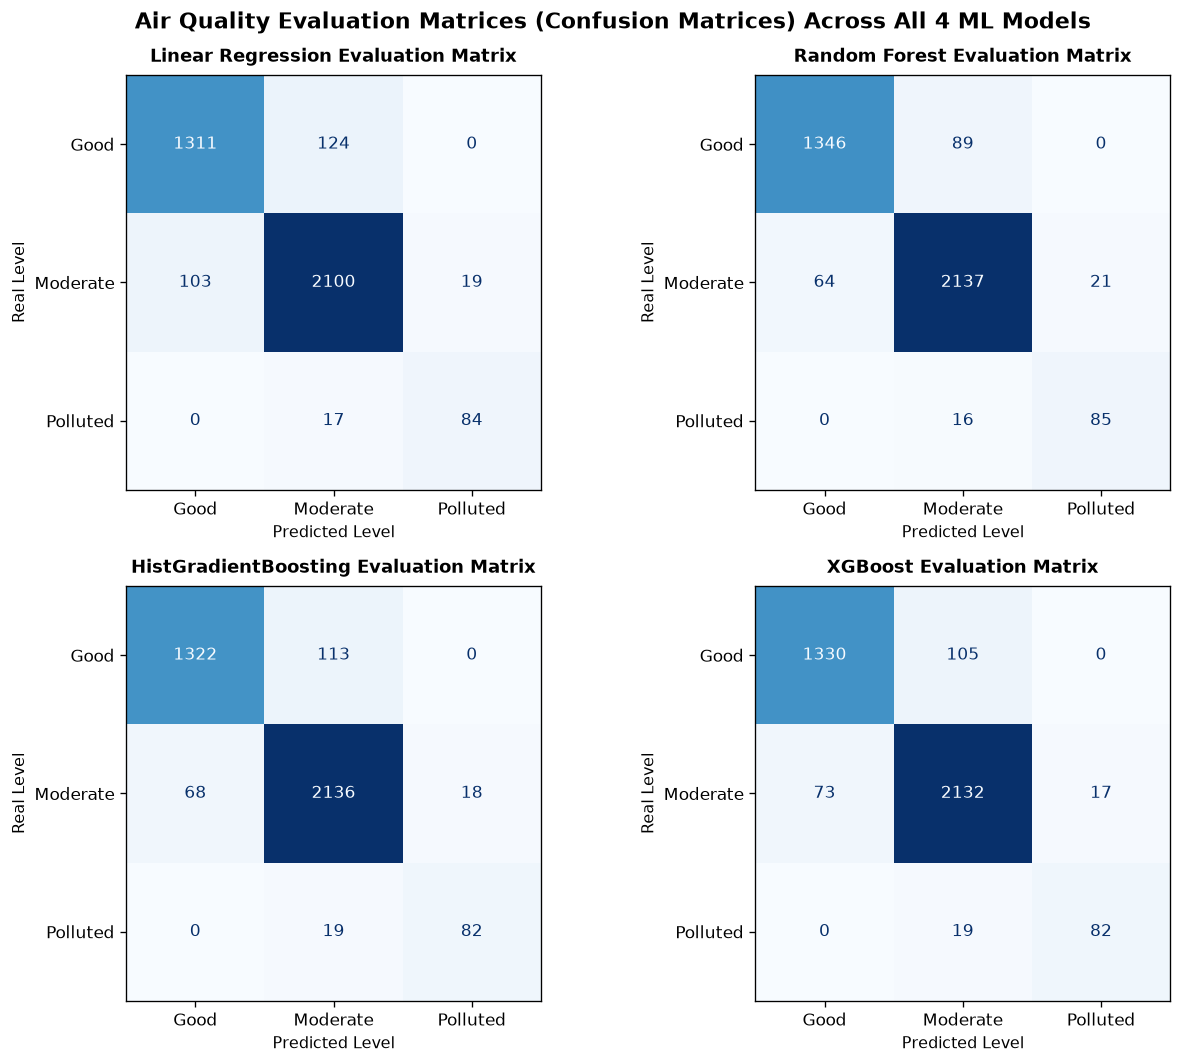

In [11]:
confusion_matrices = {}

for name in ml_names:
    safe_name = name.lower().replace(" ", "_")
    model_dir = RESULT_DIR / safe_name
    model_dir.mkdir(parents=True, exist_ok=True)  # 1 folder per ML algorithm, no duplicates

    pred_lvl = to_level(test_preds[name])
    cm = pd.DataFrame(
        confusion_matrix(true_lvl, pred_lvl, labels=LEVELS),
        index=[f"real {lvl}" for lvl in LEVELS],
        columns=[f"pred {lvl}" for lvl in LEVELS],
    )
    cm.to_csv(model_dir / "confusion_matrix.csv")
    confusion_matrices[name] = cm

    print("=" * 60)
    print(f"MODEL: {name}")
    print("=" * 60)
    print(classification_report(true_lvl, pred_lvl, labels=LEVELS, zero_division=0))
    print(cm, "\n")

    # Save individual evaluation matrix heatmap plot
    fig_m, ax_m = plt.subplots(figsize=(5.2, 4.2), dpi=140)
    disp_m = ConfusionMatrixDisplay(confusion_matrix=cm.values, display_labels=LEVELS)
    disp_m.plot(ax=ax_m, cmap="Blues", colorbar=False)
    ax_m.set_title(f"{name} — Evaluation Matrix", fontsize=11, fontweight="bold", pad=8)
    ax_m.set_xlabel("Predicted Level", fontsize=9.5)
    ax_m.set_ylabel("Real Level", fontsize=9.5)
    fig_m.tight_layout()
    fig_m.savefig(model_dir / "chart_confusion_matrix.png", dpi=140)
    plt.close(fig_m)

# Combined 2x2 Evaluation Matrix Heatmap Chart for all 4 ML Algorithms
fig_all_cm, axes_cm = plt.subplots(2, 2, figsize=(11, 9), dpi=150)
for ax, name in zip(axes_cm.flat, ml_names):
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrices[name].values, display_labels=LEVELS)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} Evaluation Matrix", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Predicted Level", fontsize=9.5)
    ax.set_ylabel("Real Level", fontsize=9.5)

fig_all_cm.suptitle("Air Quality Evaluation Matrices (Confusion Matrices) Across All 4 ML Models", fontsize=13, fontweight="bold", y=0.98)
fig_all_cm.tight_layout()
fig_all_cm.savefig(RESULT_DIR / "chart_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Visualizations for All 4 ML Algorithms
Generates both combined 4-model comparison charts in `results/` and individual charts in `results/<algorithm>/`.

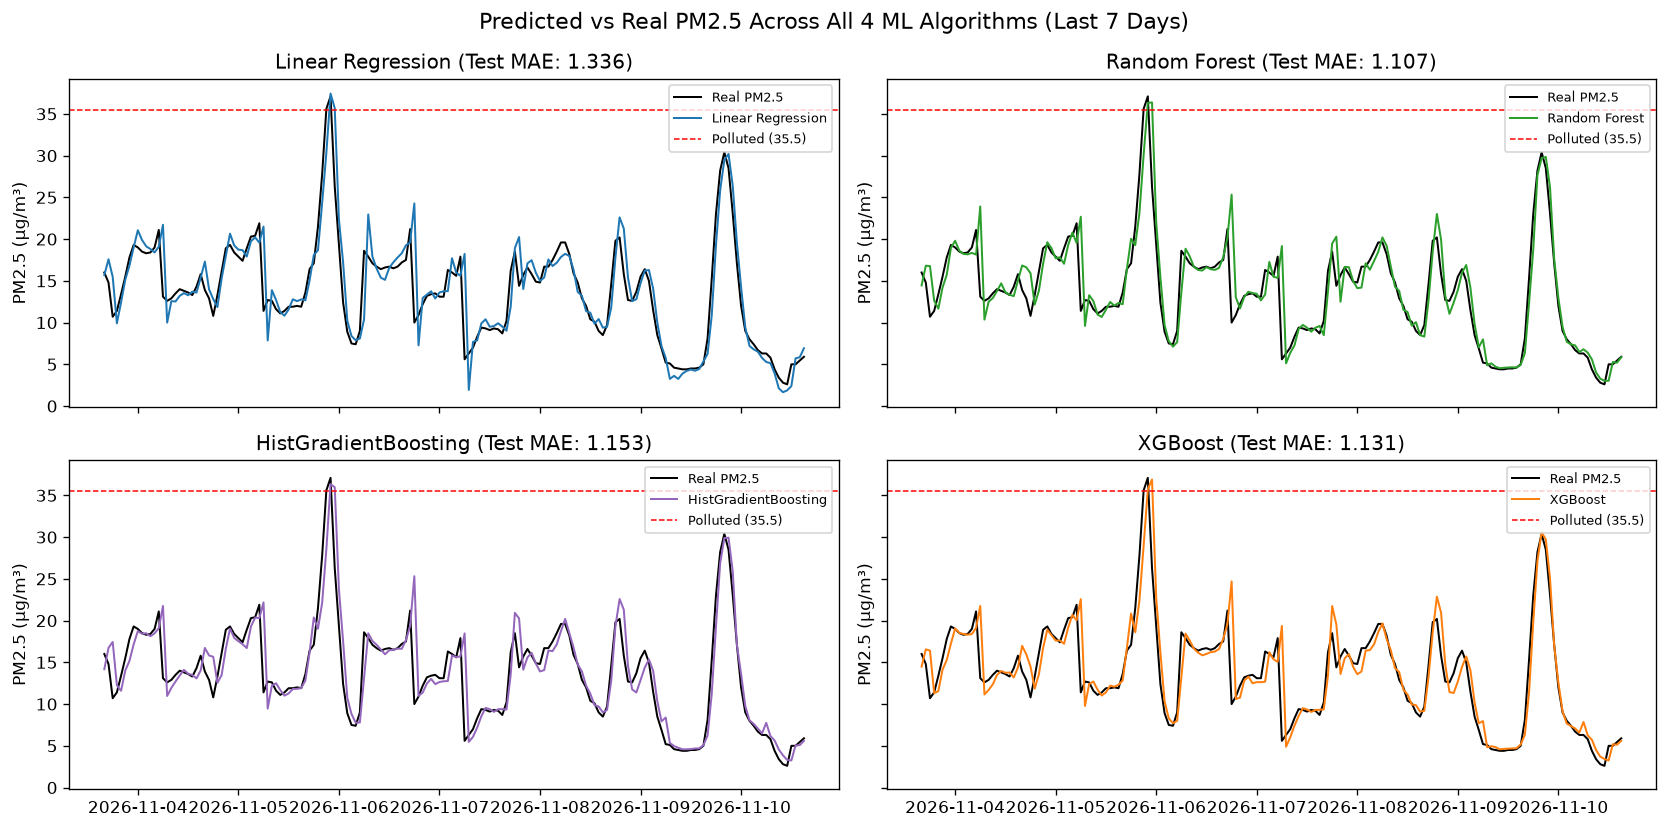

In [12]:
last_week = slice(-24 * 7, None)
colors = ["tab:blue", "tab:green", "tab:purple", "tab:orange"]

# 2x2 grid showing Predicted vs Real for each of the 4 ML Algorithms
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, name, color in zip(axes.flat, ml_names, colors):
    pred = test_preds[name]
    ax.plot(yte.index[last_week], yte.values[last_week], label="Real PM2.5", color="black", lw=1.2)
    ax.plot(yte.index[last_week], pred[last_week], label=name, color=color, lw=1.2)
    ax.axhline(MODERATE_MAX, color="red", ls="--", lw=0.9, label=f"Polluted ({MODERATE_MAX})")
    ax.set_title(f"{name} (Test MAE: {res.loc[name, 'MAE']:.3f})")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(loc="upper right", fontsize=8)

    # Save individual chart per algorithm
    safe_name = name.lower().replace(" ", "_")
    fig_single = plt.figure(figsize=(10, 3.8))
    plt.plot(yte.index[last_week], yte.values[last_week], label="Real PM2.5", color="black")
    plt.plot(yte.index[last_week], pred[last_week], label=name, color=color)
    plt.axhline(MODERATE_MAX, color="red", ls="--", lw=1, label=f"Polluted ({MODERATE_MAX})")
    plt.ylabel("PM2.5 (µg/m³)")
    plt.title(f"Predicted vs Real PM2.5 - {name} (Last 7 Days)")
    plt.legend()
    plt.tight_layout()
    fig_single.savefig(RESULT_DIR / safe_name / "chart_predicted_vs_real.png", dpi=150)
    plt.close(fig_single)

fig.suptitle("Predicted vs Real PM2.5 Across All 4 ML Algorithms (Last 7 Days)", fontsize=13)
fig.tight_layout()
fig.savefig(RESULT_DIR / "chart_predicted_vs_real.png", dpi=150)
plt.show()

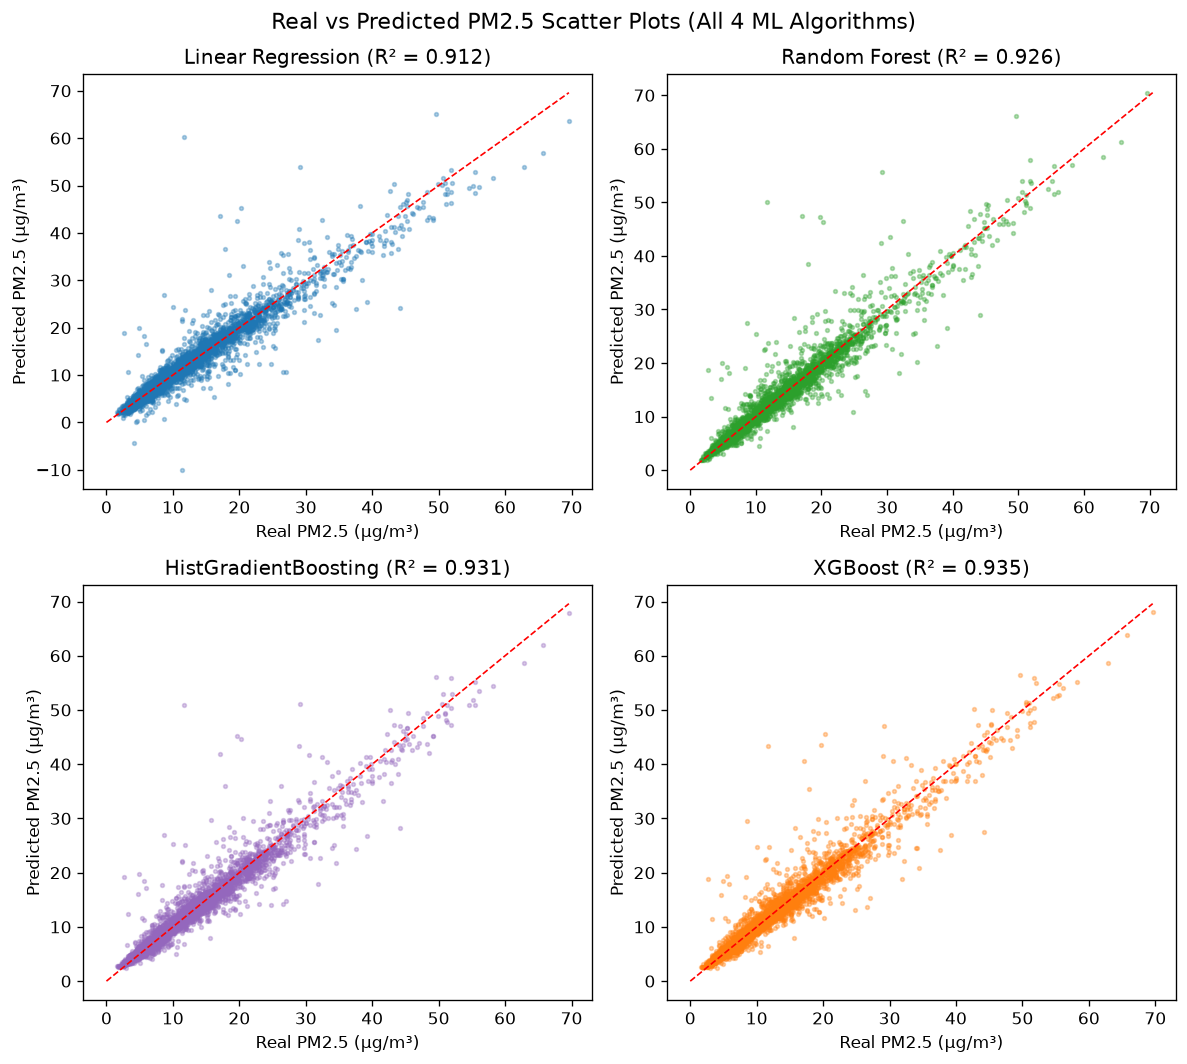

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, name, color in zip(axes.flat, ml_names, colors):
    pred = test_preds[name]
    lim = [0, max(yte.max(), pred.max())]

    ax.scatter(yte, pred, s=5, alpha=0.35, color=color)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_xlabel("Real PM2.5 (µg/m³)")
    ax.set_ylabel("Predicted PM2.5 (µg/m³)")
    ax.set_title(f"{name} (R² = {res.loc[name, 'R2']:.3f})")

    # Save individual scatter plot per algorithm
    safe_name = name.lower().replace(" ", "_")
    fig_single = plt.figure(figsize=(5, 5))
    plt.scatter(yte, pred, s=5, alpha=0.4, color=color)
    plt.plot(lim, lim, "r--", lw=1)
    plt.xlabel("Real PM2.5 (µg/m³)")
    plt.ylabel("Predicted PM2.5 (µg/m³)")
    plt.title(f"{name} (R² = {res.loc[name, 'R2']:.3f})")
    plt.tight_layout()
    fig_single.savefig(RESULT_DIR / safe_name / "chart_scatter.png", dpi=150)
    plt.close(fig_single)

fig.suptitle("Real vs Predicted PM2.5 Scatter Plots (All 4 ML Algorithms)", fontsize=13)
fig.tight_layout()
fig.savefig(RESULT_DIR / "chart_scatter.png", dpi=150)
plt.show()

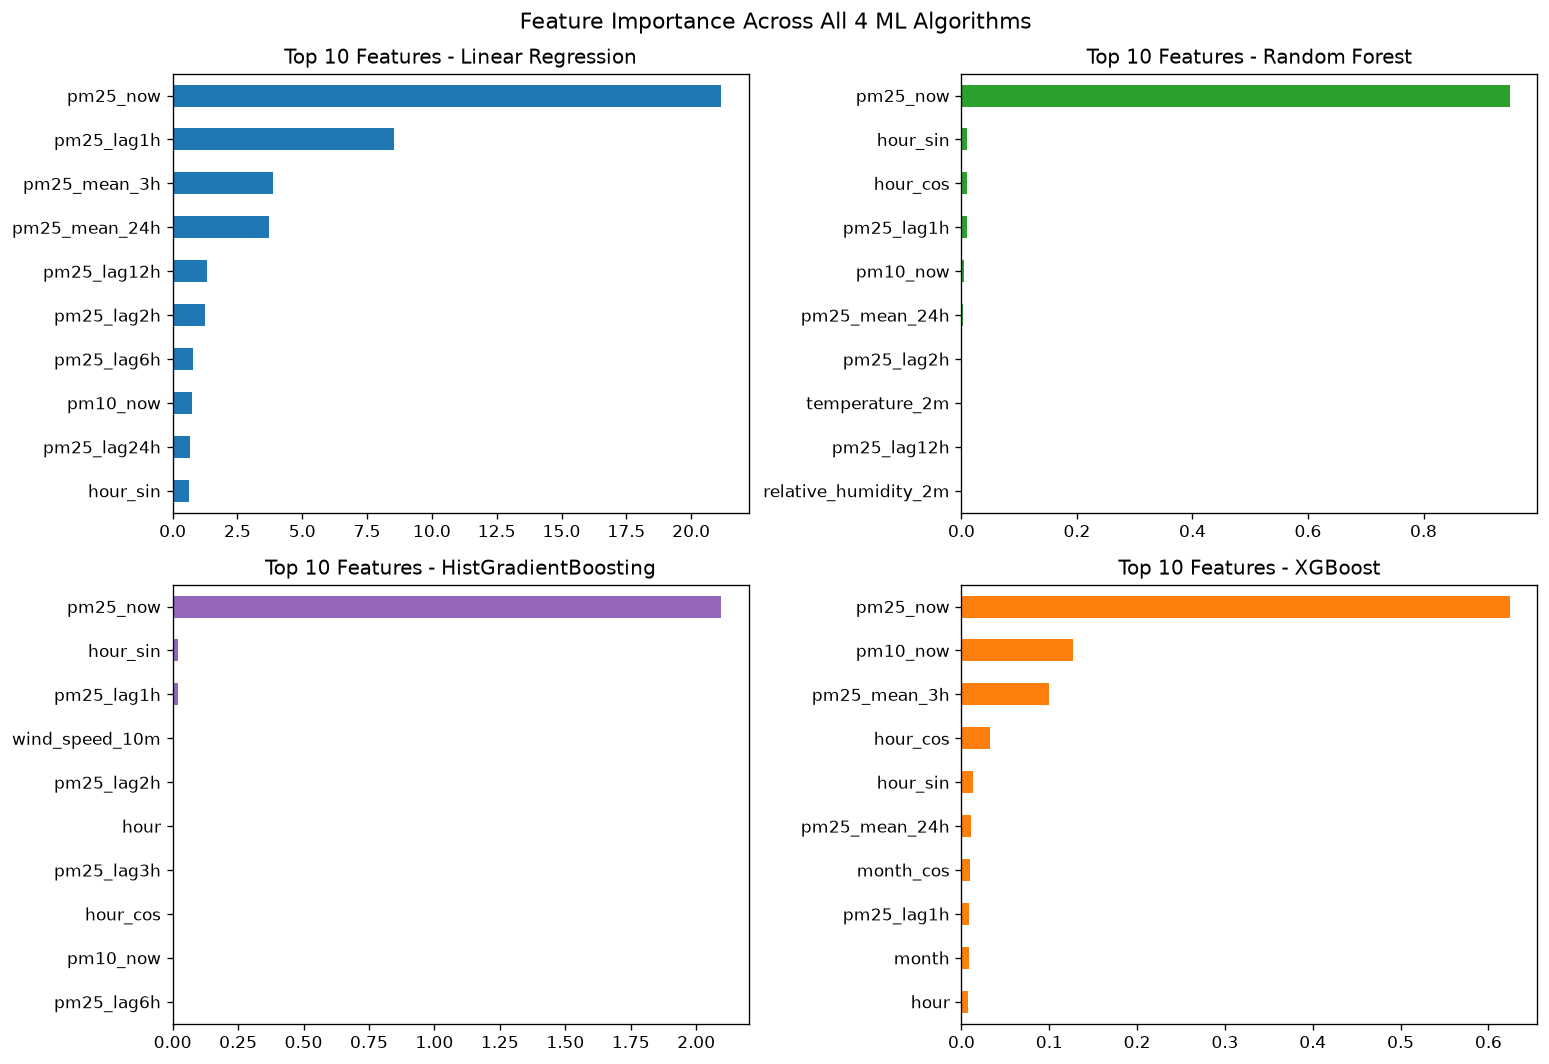

In [14]:
sample = Xte.sample(min(2000, len(Xte)), random_state=SEED)
sample_y = yte.loc[sample.index]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, name, color in zip(axes.flat, ml_names, colors):
    model = fitted[name]
    imp = get_feature_importance(model, sample, sample_y, feature_names)
    top_imp = imp.sort_values().tail(10)

    top_imp.plot.barh(ax=ax, color=color)
    ax.set_title(f"Top 10 Features - {name}")

    # Save individual feature importance plot per algorithm
    safe_name = name.lower().replace(" ", "_")
    fig_single = plt.figure(figsize=(7, 5))
    imp.sort_values().tail(15).plot.barh(color=color)
    plt.title(f"Top 15 Features ({name})")
    plt.tight_layout()
    fig_single.savefig(RESULT_DIR / safe_name / "chart_feature_importance.png", dpi=150)
    plt.close(fig_single)

fig.suptitle("Feature Importance Across All 4 ML Algorithms", fontsize=13)
fig.tight_layout()
fig.savefig(RESULT_DIR / "chart_feature_importance.png", dpi=150)
plt.show()

## 11. Save All 4 Models & 24-Hour Next-Day Forecast (+1h to +24h)

All 4 models and 24-hour forecasts saved in: D:\For Study\Year 4\AI-Engineering\Mini Project\results

=== 24-Hour Next-Day Summary Across All 4 ML Models ===
                      Pred_1h_PM25  Pred_24h_PM25  Next_24h_Mean_PM25  Next_24h_Mean_US_AQI  Next_24h_Min_PM25  Next_24h_Max_PM25 Next_24h_Level  Is_Best_Model
Model                                                                                                                                                          
Linear Regression             7.61           1.70                7.96                    44               0.00              16.95           Good          False
Random Forest                 6.98          13.10               14.19                    60               6.98              17.97       Moderate           True
HistGradientBoosting          6.82           8.94               11.78                    56               6.82              17.01       Moderate          False
XGBoost                       6.76        

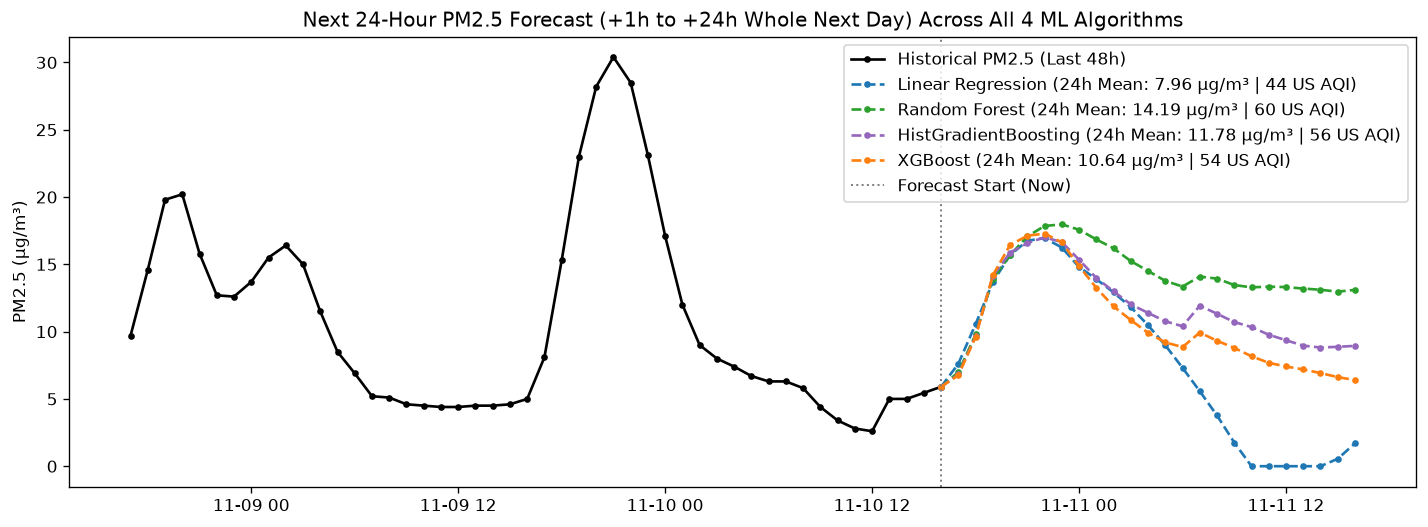

,Forecast_Time,Linear Regression_PM25,Linear Regression_US_AQI,Random Forest_PM25,Random Forest_US_AQI,HistGradientBoosting_PM25,HistGradientBoosting_US_AQI,XGBoost_PM25,XGBoost_US_AQI,Random Forest_Level
Step_Hours,,,,,,,,,,
+1h,2026-11-10 17:00,7.61,42,6.98,39,6.82,38,6.76,38,Good
+2h,2026-11-10 18:00,10.55,54,9.79,52,9.67,52,9.60,52,Moderate
+3h,2026-11-10 19:00,13.68,60,13.92,60,14.12,60,14.19,60,Moderate
+4h,2026-11-10 20:00,15.69,63,15.68,63,15.87,64,16.44,65,Moderate
+5h,2026-11-10 21:00,16.75,65,17.07,66,16.57,65,17.12,66,Moderate
+6h,2026-11-10 22:00,16.95,66,17.85,67,17.01,66,17.29,66,Moderate
+7h,2026-11-10 23:00,16.25,64,17.97,68,16.65,65,16.63,65,Moderate
+8h,2026-11-11 00:00,14.80,62,17.57,67,15.34,63,14.87,62,Moderate
+9h,2026-11-11 01:00,13.90,60,16.85,65,13.99,60,13.25,59,Moderate


In [15]:
current_time = latest_features.index[0]
current_pm = float(latest_features["pm25_now"].iloc[0])
summary_rows = []
combined_24h = pd.DataFrame({
    "Step_Hours": forecast_24h_by_model[best_name]["Step_Hours"],
    "Forecast_Time": forecast_24h_by_model[best_name]["Forecast_Time"].dt.strftime("%Y-%m-%d %H:%M"),
})

for name in ml_names:
    safe_name = name.lower().replace(" ", "_")
    model_dir = RESULT_DIR / safe_name
    model_file = model_dir / "model.joblib"
    joblib.dump(
        {
            "model_name": name,
            "model": fitted[name],
            "features": feature_names,
            "horizon_hours": 24,
        },
        model_file,
    )

    fc_df = forecast_24h_by_model[name].copy()
    fc_save = fc_df.copy()
    fc_save["Forecast_Time"] = fc_save["Forecast_Time"].dt.strftime("%Y-%m-%d %H:%M:%S")
    fc_save["Model"] = name
    fc_save.to_csv(model_dir / "future_forecast.csv", index=False)
    fc_save.to_csv(model_dir / "future_forecast_24h.csv", index=False)

    combined_24h[f"{name}_PM25"] = fc_df["Predicted_PM25"]
    combined_24h[f"{name}_US_AQI"] = fc_df["Predicted_US_AQI"]

    mean_pm = float(fc_df["Predicted_PM25"].mean())
    min_pm = float(fc_df["Predicted_PM25"].min())
    max_pm = float(fc_df["Predicted_PM25"].max())
    summary_rows.append({
        "Model": name,
        "Last_Known_Time": current_time.strftime("%Y-%m-%d %H:%M"),
        "Last_Known_PM25": round(current_pm, 2),
        "Forecast_Window_24h": f"{fc_df['Forecast_Time'].iloc[0].strftime('%Y-%m-%d %H:%M')} -> {fc_df['Forecast_Time'].iloc[-1].strftime('%Y-%m-%d %H:%M')}",
        "Pred_1h_PM25": float(fc_df["Predicted_PM25"].iloc[0]),
        "Pred_1h_US_AQI": int(fc_df["Predicted_US_AQI"].iloc[0]),
        "Pred_24h_PM25": float(fc_df["Predicted_PM25"].iloc[-1]),
        "Pred_24h_US_AQI": int(fc_df["Predicted_US_AQI"].iloc[-1]),
        "Next_24h_Mean_PM25": round(mean_pm, 2),
        "Next_24h_Mean_US_AQI": pm25_to_us_aqi(mean_pm),
        "Next_24h_Min_PM25": round(min_pm, 2),
        "Next_24h_Max_PM25": round(max_pm, 2),
        "Next_24h_Level": str(to_level(np.array([mean_pm]))[0]),
        "Is_Best_Model": name == best_name,
    })

# Also save the overall best model at the root of results/
joblib.dump(
    {
        "model_name": best_name,
        "model": fitted[best_name],
        "features": feature_names,
        "horizon_hours": 24,
    },
    RESULT_DIR / "best_model.joblib",
)

combined_24h[f"{best_name}_Level"] = forecast_24h_by_model[best_name]["Predicted_Level"]
combined_24h.set_index("Step_Hours").to_csv(RESULT_DIR / "next_24h_forecasts.csv")

forecast_summary_df = pd.DataFrame(summary_rows).set_index("Model")
forecast_summary_df.to_csv(RESULT_DIR / "next_hour_forecasts.csv")

# Plot last 48 hours of known PM2.5 + 24-hour future forecast trajectory for all 4 models
recent_series = df["pm25"].iloc[-48:]
plt.figure(figsize=(12, 4.5))
plt.plot(
    recent_series.index,
    recent_series.values,
    color="black",
    lw=1.6,
    marker="o",
    markersize=3,
    label="Historical PM2.5 (Last 48h)",
)

for name, color in zip(ml_names, colors):
    fc_df = forecast_24h_by_model[name]
    plot_times = [current_time] + list(fc_df["Forecast_Time"])
    plot_pms = [current_pm] + list(fc_df["Predicted_PM25"])
    mean_pm = float(fc_df["Predicted_PM25"].mean())
    mean_aqi = pm25_to_us_aqi(mean_pm)

    plt.plot(
        plot_times,
        plot_pms,
        ls="--",
        lw=1.6,
        marker="o",
        markersize=3,
        color=color,
        label=f"{name} (24h Mean: {mean_pm:.2f} µg/m³ | {mean_aqi} US AQI)",
    )

    # Also save individual 24-hour future forecast chart inside each model's folder
    safe_name = name.lower().replace(" ", "_")
    fig_single = plt.figure(figsize=(11, 4.0))
    plt.plot(
        recent_series.index,
        recent_series.values,
        color="black",
        lw=1.6,
        marker="o",
        markersize=3,
        label="Historical PM2.5 (Last 48h)",
    )
    plt.plot(
        plot_times,
        plot_pms,
        ls="--",
        lw=1.8,
        marker="o",
        markersize=4,
        color=color,
        label=f"Next 24h Forecast (Mean: {mean_pm:.2f} µg/m³ | {mean_aqi} US AQI)",
    )
    plt.axvline(current_time, color="gray", ls=":", lw=1.2, label="Forecast Start (Now)")
    plt.ylabel("PM2.5 (µg/m³)")
    plt.title(f"{name} - Next 24 Hours Forecast (+1h to +24h)")
    plt.legend()
    plt.tight_layout()
    fig_single.savefig(RESULT_DIR / safe_name / "chart_future_forecast.png", dpi=150)
    plt.close(fig_single)

plt.axvline(current_time, color="gray", ls=":", lw=1.2, label="Forecast Start (Now)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Next 24-Hour PM2.5 Forecast (+1h to +24h Whole Next Day) Across All 4 ML Algorithms")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / "chart_future_forecast.png", dpi=150)
plt.show()

print(f"All 4 models and 24-hour forecasts saved in: {RESULT_DIR.resolve()}\n")
print("=== 24-Hour Next-Day Summary Across All 4 ML Models ===")
print(forecast_summary_df[["Pred_1h_PM25", "Pred_24h_PM25", "Next_24h_Mean_PM25", "Next_24h_Mean_US_AQI", "Next_24h_Min_PM25", "Next_24h_Max_PM25", "Next_24h_Level", "Is_Best_Model"]].to_string())
print("\n=== Hourly Next-Day Forecast Table (+1h to +24h) ===")
combined_24h.set_index("Step_Hours")